# **MÓDULO 19**
# Exercício: Estatística Aplicada

**Efetividade de Duas Estratégias de Ensino**

Imagine que uma escola esteja avaliando a eficácia de duas estratégias de ensino de matemática para alunos do ensino médio. Eles querem determinar se há uma diferença significativa no desempenho médio dos alunos entre as duas estratégias.

# **Hipóteses:**

* Hipótese nula (H0): A média das notas dos alunos na estratégia A é igual à média das notas dos alunos na estratégia B.
* Hipótese alternativa (H1): A média das notas na Estratégia B é maior do que a média das notas na Estratégia A.

# **Dados:**

* Amostra da Estratégia A: Notas de 50 alunos que receberam a Estratégia A.
* Amostra da Estratégia B: Notas de 50 alunos que receberam a Estratégia B.

Usaremos um teste Z para comparar as médias das notas entre as duas amostras.

Se o p-valor do teste Z for menor que um nível de significância pré-determinado (por exemplo, α = 0.05), rejeitamos a hipótese nula e concluímos que há uma diferença significativa nas médias das notas entre as duas estratégias de ensino.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Os dados são criados a seguir:

In [2]:
# Definindo médias e desvios padrão para as notas nas duas estratégias
media_estrategia_A = 70
desvio_padrao_estrategia_A = 10

media_estrategia_B = 75
desvio_padrao_estrategia_B = 12

# Gerando as amostras de notas para cada estratégia de ensino da nossa base
np.random.seed(0)  # Para garantir a reprodutibilidade dos resultados
amostra_estrategia_A = np.random.normal(loc=media_estrategia_A, scale=desvio_padrao_estrategia_A, size=50)
amostra_estrategia_B = np.random.normal(loc=media_estrategia_B, scale=desvio_padrao_estrategia_B, size=50)

print("Notas da Estratégia A:", amostra_estrategia_A[:5])
print("Notas da Estratégia B:", amostra_estrategia_B[:5])

Notas da Estratégia A: [87.64052346 74.00157208 79.78737984 92.40893199 88.6755799 ]
Notas da Estratégia B: [64.25440127 79.64282997 68.87033835 60.83241379 74.66181326]


# 1) De acordo com as informações analisadas o nosso teste é unilateral á direita, esquerda ou bicaudal? Justifique.




**Resposta 1:** o teste é **unilateral à direita**.

A hipótese alternativa diz que a média da Estratégia B é **maior** que a da A (H1: μB > μA), então só me interessa uma direção. Como calculo Z = (média B − média A) / erro padrão, apenas valores grandes e positivos de Z favorecem H1. Por isso os 5% de α ficam todos na cauda direita. Se H1 dissesse apenas que as médias são diferentes, o teste seria bicaudal e o α seria dividido entre as duas caudas.

O enunciado fala em "diferença significativa", o que lembra um bicaudal, mas o que define o tipo de teste é a H1 que foi escrita, e ela aponta para B > A.

# 2) Calcule as médias para as duas amostragens e as variâncias. Quais insights você pode retirar comparando os dados?

In [3]:
# Médias e variâncias amostrais (ddof=1 -> variância amostral)
media_A = amostra_estrategia_A.mean()
media_B = amostra_estrategia_B.mean()
var_A = amostra_estrategia_A.var(ddof=1)
var_B = amostra_estrategia_B.var(ddof=1)

print(f"Estratégia A -> média: {media_A:.2f} | variância: {var_A:.2f} | desvio padrão: {np.sqrt(var_A):.2f}")
print(f"Estratégia B -> média: {media_B:.2f} | variância: {var_B:.2f} | desvio padrão: {np.sqrt(var_B):.2f}")
print(f"Diferença de médias (B - A): {media_B - media_A:.2f} pontos")

Estratégia A -> média: 71.41 | variância: 129.27 | desvio padrão: 11.37
Estratégia B -> média: 74.75 | variância: 110.47 | desvio padrão: 10.51
Diferença de médias (B - A): 3.34 pontos


**Resposta 2:**

- **Médias:** a Estratégia B ficou com média maior (≈ 74,75 contra ≈ 71,41), uma vantagem de cerca de 3,3 pontos. A direção é a esperada, mas a diferença ficou menor que os 5 pontos usados para gerar os dados (70 e 75). Isso é variação normal de amostra.
- **Variâncias:** são parecidas (≈ 129 em A e ≈ 110 em B). Os desvios padrão eram 10 (A) e 12 (B), mas na amostra A saiu um pouco mais dispersa, também por acaso.
- **Comparação:** 3,3 pontos é pouco perto da dispersão das notas (cerca de 0,3 desvio padrão), então as duas distribuições se sobrepõem bastante. Por isso espero uma evidência fraca ou moderada, e só o teste vai mostrar se essa diferença pode ser acaso.

# 3) Imprima os resultados da estatística do teste Z, p value e indique se rejeitaremos ou não a hipótese nula. Justifique sua resposta.

In [4]:
# Obs.: o scipy não traz um teste Z pronto para duas amostras, então calculamos o Z
# manualmente com a fórmula (diferença das médias / erro padrão) e usamos stats.norm para o p-value.
alpha = 0.05
n_A, n_B = len(amostra_estrategia_A), len(amostra_estrategia_B)

# Estatística Z para diferença de médias (teste unilateral à direita: H1 -> média B > média A)
erro_padrao = np.sqrt(var_A / n_A + var_B / n_B)
z_calc = (media_B - media_A) / erro_padrao

# p-value: área à direita de z_calc na normal padrão
p_valor = stats.norm.sf(z_calc)

# valor crítico para alpha = 0.05 (unilateral à direita)
z_critico = stats.norm.ppf(1 - alpha)

print(f"Erro padrão da diferença: {erro_padrao:.4f}")
print(f"Estatística Z calculada : {z_calc:.4f}")
print(f"Valor crítico (α=0.05)  : {z_critico:.4f}")
print(f"p-value                 : {p_valor:.4f}")

if p_valor < alpha:
    print("Decisão: REJEITAMOS H0 (p-value < α).")
else:
    print("Decisão: NÃO rejeitamos H0 (p-value >= α).")

# Checagem extra: Z com os desvios padrão populacionais conhecidos (10 e 12, definidos no notebook)
ep_conhecido = np.sqrt(desvio_padrao_estrategia_A**2 / n_A + desvio_padrao_estrategia_B**2 / n_B)
z_conhecido = (media_B - media_A) / ep_conhecido
print(f"\nChecagem com σ conhecido -> Z = {z_conhecido:.4f}, p-value = {stats.norm.sf(z_conhecido):.4f}")

Erro padrão da diferença: 2.1897
Estatística Z calculada : 1.5267
Valor crítico (α=0.05)  : 1.6449
p-value                 : 0.0634
Decisão: NÃO rejeitamos H0 (p-value >= α).

Checagem com σ conhecido -> Z = 1.5133, p-value = 0.0651


**Resposta 3:**

- Z calculado ≈ **1,527**, p-value ≈ **0,0634** e Z crítico ≈ **1,645** (α = 0,05, cauda direita).
- Como o p-value (0,0634) é maior que α (0,05), e o Z calculado (1,527) é menor que o crítico (1,645), **não rejeito H0**.

**Interpretação:** se as duas estratégias tivessem a mesma média, eu veria uma diferença igual ou maior que a observada em cerca de 6,3% das amostras. É pouco, mas não passa do meu critério de 5%.

**Cuidado com a conclusão:** não rejeitar H0 não prova que as estratégias são iguais. Significa apenas que estes dados não são suficientes para afirmar, com 5% de significância, que B é melhor que A. O resultado ficou perto do limite: com α = 0,10 eu rejeitaria H0.

**Por que usar o teste Z:** as duas amostras têm 50 alunos e os desvios padrão populacionais são conhecidos (10 e 12). Refiz a conta com esses desvios e o resultado foi praticamente o mesmo (Z ≈ 1,513 e p ≈ 0,065), então a decisão não depende dessa escolha.

# 4) Para finalizar monte o gráfico da distribuição da estatística do nosso teste Z e explique o que pode ser observado através dele.

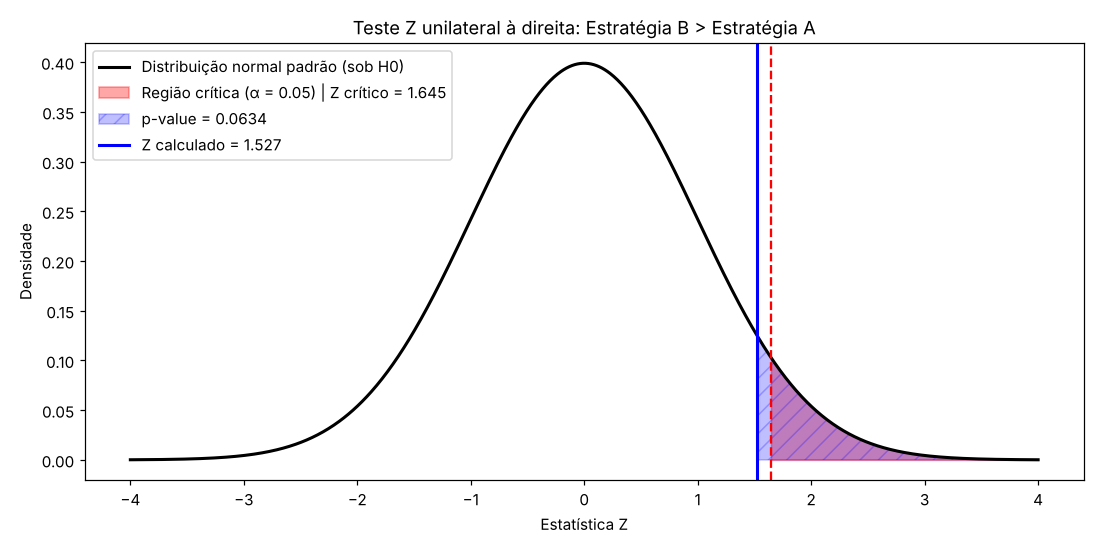

In [5]:
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, y, color="black", lw=2, label="Distribuição normal padrão (sob H0)")

# Região crítica (α = 0.05): à direita do valor crítico
ax.fill_between(x, y, where=(x >= z_critico), color="red", alpha=0.35,
                label=f"Região crítica (α = {alpha}) | Z crítico = {z_critico:.3f}")
# Área do p-value: à direita da estatística observada
ax.fill_between(x, y, where=(x >= z_calc), color="blue", alpha=0.25, hatch="//",
                label=f"p-value = {p_valor:.4f}")

ax.axvline(z_critico, color="red", ls="--", lw=1.5)
ax.axvline(z_calc, color="blue", ls="-", lw=2, label=f"Z calculado = {z_calc:.3f}")

ax.set_title("Teste Z unilateral à direita: Estratégia B > Estratégia A")
ax.set_xlabel("Estatística Z")
ax.set_ylabel("Densidade")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Resposta 4:**

- A curva é a distribuição de Z **assumindo que H0 é verdadeira** (normal padrão). A área vermelha, à direita de 1,645, é a região crítica e vale 5% da curva.
- A linha azul marca o Z que calculei (1,527). Ela cai **antes** da região crítica, então não rejeito H0.
- A área hachurada à direita da linha azul é o **p-value (≈ 6,3%)**. Ela é maior que a área vermelha (5%), e é exatamente isso que significa p-value > α.
- O gráfico também mostra que o resultado foi **por pouco**: o Z observado ficou perto do valor crítico, então outra amostra poderia ter levado à rejeição.
- Na população simulada a diferença real é de 5 pontos. Com 50 alunos por grupo, o teste detectaria esse efeito em cerca de 73% das amostras, então não ter rejeitado H0 aqui não indica que não exista diferença.

# 5) Bônus: visualização interativa (React + Tailwind CSS)

Para explorar o que você calculou nas questões 2 a 4, execute a célula abaixo. Ela abre um painel interativo com duas abas:

- **Teste Z (Estratégia A × B):** os controles já começam com as médias, variâncias, n e α calculados neste notebook. Mude o tamanho da amostra, o α ou o tipo de cauda e veja a região crítica, o p-value e a decisão mudarem no gráfico.
- **Discreta × contínua:** compara a PMF de uma distribuição de Poisson (contagens) com a curva da normal.

Requisitos: execute antes as células das questões 2 e 3 (o painel usa `media_A`, `media_B`, `var_A`, `var_B`, `n_A` e `alpha`) e esteja conectado à internet, porque React e Tailwind são carregados de CDNs. Esta seção é um complemento e não substitui as respostas das questões 1 a 4.

In [ ]:
#@title Visualização interativa (React + Tailwind CSS) { display-mode: "form" }
import json, html as _html
from IPython.display import HTML, display

# Os controles começam com os valores calculados nas questões 2 e 3
_INIT = {
    "mA": round(float(media_A), 2), "mB": round(float(media_B), 2),
    "vA": round(float(var_A), 2),   "vB": round(float(var_B), 2),
    "n": int(n_A), "alpha": float(alpha), "tail": "right",
}

_PAGE = r"""<!DOCTYPE html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>Laboratório de Estatística: Teste Z</title>
<script src="https://cdn.tailwindcss.com/3.4.17"></script>
<script src="https://cdn.jsdelivr.net/npm/react@18.3.1/umd/react.production.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/react-dom@18.3.1/umd/react-dom.production.min.js"></script>
<style>
:root{--bg:#f6f7fb;--card:#ffffff;--fg:#14171f;--muted:#5b6475;--line:#d9deea;--accent:#2f5bea;--crit:#e5484d;--ok:#1f9d63;--warn:#b7791f;--curve:#14171f;
  box-sizing:border-box;padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}
@media (prefers-color-scheme: dark){:root:not([data-theme="light"]){--bg:#0f1219;--card:#181c26;--fg:#e9ecf4;--muted:#9aa3b5;--line:#2a3040;--accent:#7b96ff;--crit:#ff6b70;--ok:#3ecf8e;--warn:#e6b450;--curve:#e9ecf4}}
:root[data-theme="dark"]{--bg:#0f1219;--card:#181c26;--fg:#e9ecf4;--muted:#9aa3b5;--line:#2a3040;--accent:#7b96ff;--crit:#ff6b70;--ok:#3ecf8e;--warn:#e6b450;--curve:#e9ecf4}
html{scroll-padding-top:env(safe-area-inset-top,0px)}
body{margin:0;background:var(--bg);color:var(--fg);font-family:system-ui,-apple-system,"Segoe UI",Roboto,sans-serif}
.card{background:var(--card);border:1px solid var(--line);border-radius:14px}
.muted{color:var(--muted)}
.tab{border:1px solid var(--line);background:var(--card);color:var(--muted)}
.tab[aria-selected="true"]{background:var(--accent);border-color:var(--accent);color:#fff}
.btn{border:1px solid var(--line);background:var(--card);color:var(--fg)}
.num{font-variant-numeric:tabular-nums}
</style>
</head>
<body>
<div id="root"></div>
<script>
const { useState } = React;
const h = React.createElement;

/* ---------- matemática ---------- */
function erf(x){const s=Math.sign(x);x=Math.abs(x);const t=1/(1+0.3275911*x);
  const y=1-(((((1.061405429*t-1.453152027)*t)+1.421413741)*t-0.284496736)*t+0.254829592)*t*Math.exp(-x*x);return s*y;}
const cdf = z => 0.5*(1+erf(z/Math.SQRT2));
const pdf = z => Math.exp(-z*z/2)/Math.sqrt(2*Math.PI);
function ppf(p){let lo=-8,hi=8;for(let i=0;i<60;i++){const m=(lo+hi)/2;if(cdf(m)<p)lo=m;else hi=m;}return (lo+hi)/2;}
const fmt = (x,d=2) => x.toFixed(d).replace('.',',');
const pct = x => fmt(x*100,2)+'%';

/* ---------- componentes ---------- */
function Slider(p){
  return h('label',{className:'block'},
    h('div',{className:'flex justify-between text-sm'},
      h('span',{className:'muted'},p.label),
      h('span',{className:'font-semibold num'},p.show?p.show(p.value):p.value)),
    h('input',{type:'range',min:p.min,max:p.max,step:p.step,value:p.value,className:'w-full',
      style:{accentColor:'var(--accent)'},onChange:e=>p.onChange(parseFloat(e.target.value))}));
}

function Stat(p){
  return h('div',{className:'card p-3'},
    h('div',{className:'text-xs muted'},p.label),
    h('div',{className:'text-xl font-bold num',style:{color:p.color||'var(--fg)'}},p.value));
}

/* ---------- aba 1: teste Z ---------- */
const INIT = __INIT__;

function ZLab(){
  const [s,setS] = useState(INIT);
  const set = k => v => setS(o=>({...o,[k]:v}));
  const se = Math.sqrt(s.vA/s.n + s.vB/s.n);
  const z = (s.mB - s.mA)/se;
  let p, crit, regs, pregs;
  const cl = v => Math.max(-4,Math.min(4,v));
  if(s.tail==='right'){p=1-cdf(z);crit=[ppf(1-s.alpha)];regs=[[crit[0],4]];pregs=[[cl(z),4]];}
  else if(s.tail==='left'){p=cdf(z);crit=[ppf(s.alpha)];regs=[[-4,crit[0]]];pregs=[[-4,cl(z)]];}
  else{p=2*(1-cdf(Math.abs(z)));const c=ppf(1-s.alpha/2);crit=[-c,c];regs=[[-4,-c],[c,4]];pregs=[[-4,-cl(Math.abs(z))],[cl(Math.abs(z)),4]];}
  const reject = p < s.alpha;
  const h1 = {right:'μB > μA',left:'μB < μA',two:'μB ≠ μA'}[s.tail];

  const W=640,H=250,L=20,R=20,T=16,B=34,YM=0.42;
  const sx = x => L+(x+4)/8*(W-L-R);
  const sy = y => H-B-y/YM*(H-B-T);
  const area = ([a,b]) => { if(b<=a) return ''; let d='M'+sx(a)+','+sy(0);
    for(let i=0;i<=60;i++){const x=a+(b-a)*i/60;d+='L'+sx(x)+','+sy(pdf(x));} return d+'L'+sx(b)+','+sy(0)+'Z'; };
  let line=''; for(let i=0;i<=160;i++){const x=-4+8*i/160;line+=(i?'L':'M')+sx(x)+','+sy(pdf(x));}
  const zc = cl(z);

  const svg = h('svg',{viewBox:`0 0 ${W} ${H}`,className:'w-full',role:'img','aria-label':'Distribuição normal padrão com região crítica e p-value'},
    h('defs',null,h('pattern',{id:'hatch',width:6,height:6,patternUnits:'userSpaceOnUse',patternTransform:'rotate(45)'},
      h('rect',{width:3,height:6,style:{fill:'var(--accent)'},opacity:.6}))),
    regs.map((r,i)=>h('path',{key:'c'+i,d:area(r),style:{fill:'var(--crit)'},opacity:.3})),
    pregs.map((r,i)=>h('path',{key:'p'+i,d:area(r),fill:'url(#hatch)'})),
    h('path',{d:line,fill:'none',style:{stroke:'var(--curve)'},strokeWidth:2}),
    h('line',{x1:L,x2:W-R,y1:sy(0),y2:sy(0),style:{stroke:'var(--line)'}}),
    [-3,-2,-1,0,1,2,3].map(t=>h('g',{key:t},
      h('line',{x1:sx(t),x2:sx(t),y1:sy(0),y2:sy(0)+5,style:{stroke:'var(--muted)'}}),
      h('text',{x:sx(t),y:sy(0)+20,textAnchor:'middle',fontSize:12,style:{fill:'var(--muted)'}},t))),
    crit.map((c,i)=>h('line',{key:'cl'+i,x1:sx(c),x2:sx(c),y1:sy(0.40),y2:sy(0),strokeDasharray:'5 4',strokeWidth:1.5,style:{stroke:'var(--crit)'}})),
    h('line',{x1:sx(zc),x2:sx(zc),y1:sy(0.40),y2:sy(0),strokeWidth:2.5,style:{stroke:'var(--accent)'}}),
    h('text',{x:sx(zc)+(zc>2.5?-6:6),y:sy(0.40)+4,textAnchor:zc>2.5?'end':'start',fontSize:13,fontWeight:700,style:{fill:'var(--accent)'}},'Z = '+fmt(z,2)));

  const decisao = reject ? 'Rejeita H0' : 'Não rejeita H0';
  return h('div',{className:'grid gap-4 lg:grid-cols-5'},
    h('div',{className:'card p-4 grid gap-3 lg:col-span-2 content-start'},
      h('div',{className:'font-semibold'},'Parâmetros'),
      h(Slider,{label:'Média A',value:s.mA,min:60,max:90,step:0.01,show:v=>fmt(v),onChange:set('mA')}),
      h(Slider,{label:'Média B',value:s.mB,min:60,max:90,step:0.01,show:v=>fmt(v),onChange:set('mB')}),
      h(Slider,{label:'Variância A',value:s.vA,min:20,max:300,step:0.01,show:v=>fmt(v),onChange:set('vA')}),
      h(Slider,{label:'Variância B',value:s.vB,min:20,max:300,step:0.01,show:v=>fmt(v),onChange:set('vB')}),
      h(Slider,{label:'Tamanho de cada amostra (n)',value:s.n,min:10,max:300,step:1,onChange:set('n')}),
      h(Slider,{label:'Nível de significância (α)',value:s.alpha,min:0.01,max:0.2,step:0.01,show:v=>fmt(v,2),onChange:set('alpha')}),
      h('div',{className:'flex gap-2 flex-wrap'},
        [['right','À direita'],['left','À esquerda'],['two','Bicaudal']].map(([k,t])=>
          h('button',{key:k,className:'tab rounded-lg px-3 py-1.5 text-sm','aria-selected':s.tail===k,onClick:()=>set('tail')(k)},t))),
      h('button',{className:'btn rounded-lg px-3 py-2 text-sm',onClick:()=>setS(INIT)},'Voltar aos dados do exercício')),
    h('div',{className:'lg:col-span-3 grid gap-3 content-start'},
      h('div',{className:'card p-3'},
        h('div',{className:'text-sm muted mb-1'},'H0: μA = μB   |   H1: '+h1),
        svg,
        h('div',{className:'flex flex-wrap gap-x-4 gap-y-1 text-xs muted px-1'},
          h('span',null,h('b',{style:{color:'var(--crit)'}},'■ '),'região crítica (α)'),
          h('span',null,h('b',{style:{color:'var(--accent)'}},'▨ '),'área do p-value'),
          h('span',null,h('b',{style:{color:'var(--accent)'}},'│ '),'Z calculado'))),
      h('div',{className:'grid grid-cols-2 sm:grid-cols-4 gap-3'},
        h(Stat,{label:'Z calculado',value:fmt(z,3)}),
        h(Stat,{label:crit.length>1?'Z crítico (±)':'Z crítico',value:fmt(Math.abs(crit[0]),3)}),
        h(Stat,{label:'p-value',value:fmt(p,4)}),
        h(Stat,{label:'Decisão',value:decisao,color:reject?'var(--ok)':'var(--warn)'})),
      h('p',{className:'card p-3 text-sm'},
        'p-value = ',h('b',null,pct(p)),(reject?' < ':' ≥ '),'α = ',h('b',null,pct(s.alpha)),'. ',
        reject
          ? 'Dados tão extremos seriam raros se H0 fosse verdadeira, então rejeitamos H0.'
          : 'Dados assim não são raros o bastante sob H0 para o critério adotado, então não rejeitamos H0 (isso não prova que as médias são iguais).',
        h('span',{className:'muted'},' Experimente aumentar n ou trocar a cauda para ver a decisão mudar.'))));
}

/* ---------- aba 2: discreta × contínua ---------- */
function Discrete(){
  const [mu,setMu] = useState(3);
  const [curve,setCurve] = useState(true);
  const K=26, pm=[]; let q=Math.exp(-mu);
  for(let k=0;k<K;k++){pm.push(q);q=q*mu/(k+1);}
  const nrm = x => Math.exp(-(x-mu)*(x-mu)/(2*mu))/Math.sqrt(2*Math.PI*mu);
  const ymax = Math.max(...pm, nrm(mu))*1.15;
  const W=640,H=250,L=20,R=20,T=14,B=34;
  const sx = x => L+(x+0.5)/(K)*(W-L-R);
  const sy = y => H-B-y/ymax*(H-B-T);
  const bw = (W-L-R)/K*0.7;
  let line=''; for(let i=0;i<=200;i++){const x=-0.5+K*i/200;line+=(i?'L':'M')+sx(x)+','+sy(nrm(x));}
  const k0 = Math.round(mu);
  const svg = h('svg',{viewBox:`0 0 ${W} ${H}`,className:'w-full',role:'img','aria-label':'Barras da PMF de Poisson e curva normal'},
    pm.map((v,k)=>h('rect',{key:k,x:sx(k)-bw/2,y:sy(v),width:bw,height:sy(0)-sy(v),rx:2,
      style:{fill:'var(--accent)'},opacity:k===k0?1:.55})),
    curve && h('path',{d:line,fill:'none',strokeWidth:2,strokeDasharray:'6 4',style:{stroke:'var(--crit)'}}),
    h('line',{x1:L,x2:W-R,y1:sy(0),y2:sy(0),style:{stroke:'var(--line)'}}),
    [0,5,10,15,20,25].map(t=>h('text',{key:t,x:sx(t),y:sy(0)+20,textAnchor:'middle',fontSize:12,style:{fill:'var(--muted)'}},t)));
  const soma = pm.reduce((a,b)=>a+b,0);
  return h('div',{className:'grid gap-4 lg:grid-cols-5'},
    h('div',{className:'card p-4 grid gap-3 lg:col-span-2 content-start'},
      h('div',{className:'font-semibold'},'Contagens (variável discreta)'),
      h(Slider,{label:'Média de eventos (μ)',value:mu,min:0.5,max:12,step:0.5,show:v=>fmt(v,1),onChange:setMu}),
      h('label',{className:'flex items-center gap-2 text-sm'},
        h('input',{type:'checkbox',checked:curve,onChange:e=>setCurve(e.target.checked),style:{accentColor:'var(--accent)'}}),
        'Sobrepor curva normal (densidade)'),
      h('p',{className:'text-sm muted'},
        'Barras: PMF da Poisson, onde cada barra já é uma probabilidade. Curva tracejada: PDF da normal com a mesma média e variância, onde a altura é densidade e probabilidade é área.')),
    h('div',{className:'lg:col-span-3 grid gap-3 content-start'},
      h('div',{className:'card p-3'},svg),
      h('div',{className:'grid grid-cols-2 gap-3'},
        h(Stat,{label:`P(X = ${k0})`,value:pct(pm[k0])}),
        h(Stat,{label:'Soma das barras',value:fmt(soma,3)})),
      h('p',{className:'card p-3 text-sm'},
        'Com μ pequeno, a normal “vaza” para valores negativos e não descreve bem as contagens; com μ grande a Poisson se aproxima do formato da normal. Mesmo assim, para contagens use a distribuição discreta.')));
}

/* ---------- app ---------- */
function App(){
  const [tab,setTab] = useState('z');
  return h('main',{className:'max-w-5xl mx-auto px-4 py-6 grid gap-4'},
    h('header',null,
      h('h1',{className:'text-2xl font-bold'},'Laboratório de Estatística'),
      h('p',{className:'muted text-sm'},'Mexa nos controles e veja como o teste Z e as distribuições reagem.')),
    h('div',{className:'flex gap-2',role:'tablist'},
      [['z','Teste Z (Estratégia A × B)'],['d','Discreta × contínua']].map(([k,t])=>
        h('button',{key:k,role:'tab',className:'tab rounded-lg px-4 py-2 text-sm font-medium','aria-selected':tab===k,onClick:()=>setTab(k)},t))),
    tab==='z' ? h(ZLab) : h(Discrete));
}
ReactDOM.createRoot(document.getElementById('root')).render(h(App));
</script>
</body>
</html>
"""

_PAGE = _PAGE.replace("__INIT__", json.dumps(_INIT))

# O iframe isola o CSS do Tailwind e o React do restante do notebook
display(HTML(
    '<iframe srcdoc="' + _html.escape(_PAGE, quote=True) + '" '
    'width="100%" height="780" style="border:1px solid #cfd4e0;border-radius:10px"></iframe>'
))